**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**04 | MATLAB-Native Conversion and Biomechanical Signal Validation**

![Original Essex native conversion and signal-validation workflow](../../images/04_workflow.svg)

**Research objective:** Establish an independently auditable source registry and a numerical-export validation contract for the original Essex dataset (Hollinger et al., 2026, [Scientific Data](https://doi.org/10.1038/s41597-026-07429-3); [Figshare v13](https://doi.org/10.6084/m9.figshare.30225739.v13)). The source comprises 40 participants, 1,897 original movement records and six activities; the smaller 444-record derivative is not substituted.

**Verified outcome of this execution:** Original source integrity **PASSED**, with 168 empty FE representations. No numerical-export archive was supplied, so the recorded gate is `AWAITING_NATIVE_EXPORT` and validated IMU/FE payload count is **zero**. This is the historical result of this audit, **not a requirement to use MATLAB**.

**Current continuation:** [Notebook 05](05_python_first_matlab_object_decoding.ipynb) tests Python-first object decoding with `mat-io`. Its first pilot has recovered original 101 × 43 IMU and 11 × 3 FE DataFrames, but additional column types and time-index semantics must be verified. The MATLAB exporter remains an optional fallback.

**Scientific boundaries:** Reading a source object does not establish IMU physical units, original channel identities, FE strain semantics or temporal alignment. No interpolation, regression training or independent performance evaluation was conducted here.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}


# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}

/content
/content/human-movement-intelligence


**01. Imports and Environment**

The standard `setup_colab()` function registers the study-specific `code/src` directory. All research modules are imported directly from the repository, without download, cache or Git commands. Start from a new Colab runtime and a fresh clone when running a newly updated notebook: the approved `00. Colab Repository Setup` deliberately does not update an existing checkout.

In [2]:
# ======================== 01. Imports and Environment ========================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")

# ---------------- 2. Standard Library and Scientific Packages ----------------
import json
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.io import loadmat
from IPython.display import display
import matplotlib.pyplot as plt

# ---------- 3. Reusable Scientific and Native-Conversion Utilities -----------
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab
from essex_native_conversion import (
    EXPORT_COLUMNS, find_native_archive, sha256_file,
    unpack_native_archive, validate_native_manifest,
    validate_numeric_payloads, conversion_summary,
)

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4))

# ------------------- 4. Source and Study Output Locations --------------------
study_dir = root / "biomechanical_load_estimation"
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
export_dir = raw_dir / "native_export_v13"
output_dir = study_dir / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Study:", study_dir.name)
print("MATLAB conversion source:", study_dir / "code/matlab/export_essex_native_tables.m")
print("Research output directory:", output_dir)

Study: biomechanical_load_estimation
MATLAB conversion source: /content/human-movement-intelligence/biomechanical_load_estimation/code/matlab/export_essex_native_tables.m
Research output directory: /content/human-movement-intelligence/biomechanical_load_estimation/output


**02. Frozen Provenance and Original Participant Registry**

The original six-activity Essex source is identified by its pinned Figshare article version and the SHA256 previously saved in the Notebook 02 and 03 reports. The approved record registry contains `subject_id`, the original file name, a zero-based record index, activity, original `UpdatedTrialID` and FE representation status.

The source integrity gate and the numeric-conversion gate are **independent**. A correctly aligned register does not establish that MATLAB tables have been numerically recovered.

In [3]:
# =========== 02. Frozen Figshare and Participant Identity Contract ===========

# -------------------- 1. Read Approved Source Audit Files --------------------
prior02_path = output_dir / "02_record_provenance_and_quality_gate.json"
prior03_path = output_dir / "03_numeric_recovery_quality_gate.json"
registry_path = output_dir / "02_original_record_registry.csv"
for p in [prior02_path, prior03_path, registry_path]:
    if not p.is_file():
        raise FileNotFoundError(f"Required approved source evidence missing: {p}")
prior02 = json.loads(prior02_path.read_text(encoding="utf-8"))
prior03 = json.loads(prior03_path.read_text(encoding="utf-8"))
registry = pd.read_csv(
    registry_path,
    dtype={"subject_id":"string", "source_file":"string",
           "updated_trial_id":"string", "task":"string",
           "local_record_key":"string"},
)

# ---------------------- 2. Enforce Exact Source Lineage ----------------------
assert prior02["source_article_id"] == prior03["figshare_article"] == 30225739
assert prior02["version"] == prior03["dataset_version"] == 13
assert prior02["archive_sha256"] == prior03["archive_sha256"]
assert prior02["source_registry_gate"] == prior03["data_integrity_gate"] == "PASSED"
assert len(registry) == 1897 and registry["subject_id"].nunique() == 40
assert registry["local_record_key"].is_unique
print("Original source record identity: VERIFIED")
print("Original movement records:", len(registry))
print("Original participants:", registry["subject_id"].nunique())

Original source record identity: VERIFIED
Original movement records: 1897
Original participants: 40


**03. Biomechanical Data and Native Conversion Contract**

The publication describes 7 IMU sensors (3 accelerometer and 3 gyroscope axes per sensor), yielding 42 channels, and 101 positions in the time-normalised movement cycle. FE principal strains `e1/e3` are **model-derived**, calculated more sparsely than the input signals. Importantly, 168 original `e1e3` source fields were empty in the approved structural audit.

The source file `IMU` and `e1e3` objects may be native MATLAB tables. The companion MATLAB exporter and the Python-first investigation in Notebook 05 pursue alternative extraction routes. Any accepted output must preserve original table column names, finite values and the source-record identity, and must report unsupported classes and empty FE targets rather than silently converting them. The conversion contract is separate from a completed supervised dataset.

In [4]:
# ============ 03. Published Modality Contract and Missing Targets ============

# ------------- 1. Summarise Original FE Availability by Activity -------------
original_fe = (
    registry.groupby(["task", "fe_representation"])
    .size().rename("records").reset_index()
)
assert original_fe["records"].sum() == 1897
assert registry["fe_representation"].eq("empty").sum() == 168
display(original_fe)

# ------------ 2. Record Required Numerical and Scientific Checks -------------
contract = pd.DataFrame([
    {"modality":"IMU", "records":1897, "published_channels":42,
     "published_time_grid":"101 normalised points",
     "unit_and_axis_verification":"pending"},
    {"modality":"FE", "records":1897, "published_channels":2,
     "published_time_grid":"every 10th position; verify original grid",
     "unit_and_axis_verification":"pending"},
])
contract.to_csv(output_dir / "04_expected_conversion_contract.csv",index=False)
display(contract)

,task,fe_representation,records
0,BilateralHopping,empty,51
1,BilateralHopping,structured_or_opaque,300
2,CounterJumps,empty,27
3,CounterJumps,structured_or_opaque,331
4,Running,empty,27
5,Running,structured_or_opaque,333
6,SquatJumps,empty,27
7,SquatJumps,structured_or_opaque,333
8,UnilateralHopping,empty,27
9,UnilateralHopping,structured_or_opaque,321


,modality,records,published_channels,published_time_grid,unit_and_axis_verification
0,IMU,1897,42,101 normalised points,pending
1,FE,1897,2,every 10th position; verify original grid,pending


**04. Python-First Recovery and Optional MATLAB-Native Handoff**

**Preferred next investigation:** [Notebook 05](05_python_first_matlab_object_decoding.ipynb) attempts to decode the original MAT objects directly in Python using `mat-io`. Its success or failure must be determined by a source-identified numerical pilot; no Python recovery was established by the saved Notebook 04 execution.

**Fallback converter:** The MATLAB script at `biomechanical_load_estimation/code/matlab/export_essex_native_tables.m` remains available if direct Python recovery cannot be validated. This optional script runs in **MATLAB Online or MATLAB Desktop**, not in ordinary Python Colab. It exports only genuinely numeric source tables and preserves original participant/activity/trial identities.

MathWorks [MATLAB Online](https://matlab.mathworks.com/) can operate in a browser, including a basic free access tier subject to a monthly time allowance. [MATLAB Online access details](https://www.mathworks.com/products/matlab-online/matlab-online-versions.html). The original `MATLAB.zip` file is available from Figshare v13 with published file ID `63190690`.

**Optional fallback only: commands to run in MATLAB Online/Desktop, in a clean working folder:**

```matlab
websave('MATLAB.zip','https://ndownloader.figshare.com/files/63190690');
unzip('MATLAB.zip','essex_source');

websave('export_essex_native_tables.m', ...
 'https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/biomechanical_load_estimation/code/matlab/export_essex_native_tables.m');

export_essex_native_tables('essex_source','essex_native_export_v13');
```

The MATLAB script is designed to produce `native_essex_export.zip` and an original-ID-based `export_manifest.csv`. The Python-first pathway in Notebook 05 may produce the same validation **file layout** if its strict pilot succeeds; its readme must explicitly identify **Python mat-io** rather than claim MATLAB-native provenance. Supply only a genuinely validated export at `/content/native_essex_export.zip` (or under the private raw-data folder) before rerunning Notebook 04. Do not commit raw MAT files or numeric export ZIPs to GitHub.

**No export supplied:** This notebook remains a complete, correctly archived **pre-conversion audit** and reports `AWAITING_NATIVE_EXPORT`. Direct Python recovery is investigated in Notebook 05; MATLAB remains optional. Neither route is considered successful until real numeric arrays, identities and scientific semantics have been verified.

In [5]:
# ================== 04. Original MATLAB Export Availability ==================

# ------------ 1. Inspect the Version-Controlled Native Converter -------------
matlab_source = study_dir / "code" / "matlab" / "export_essex_native_tables.m"
if matlab_source.is_file():
    print("MATLAB-native converter available in local repository:", matlab_source.name)
else:
    # Conversion runs in MATLAB Online/Desktop, not in this Colab runtime.
    print("MATLAB-native converter not found in this local checkout.")
    print("It is available in the current GitHub repository;")
    print("the Python pre-conversion audit can proceed without it.")

# ---------- 2. Resolve a Single Optional Converted Numeric Archive -----------
native_archive = find_native_archive(raw_dir)
has_export = native_archive is not None
print("MATLAB-native ZIP supplied:", has_export)
if has_export:
    print("Source conversion archive SHA256:", sha256_file(native_archive))
else:
    print("Conversion status: AWAITING_NATIVE_EXPORT")
    print("No numeric source signals will be invented.")

MATLAB-native converter available in local repository: export_essex_native_tables.m
MATLAB-native ZIP supplied: False
Conversion status: AWAITING_NATIVE_EXPORT
No numeric source signals will be invented.


**05. Safe Numeric Export Extraction and Record-Level Alignment**

A supplied export ZIP is checked against a strict manifest and approved folder structure, with limits on archive size, path traversal and duplicate members. The manifest must account for both `IMU` and `FE` for each of the 1,897 original source records. It is joined to the frozen approved registry using explicit original source keys, not tensor row order.

When a numeric export file is absent, the saved output tables correctly report `awaiting_native_export`. This is a status label from the Notebook 04 validation contract, **not** a requirement to use the MATLAB software. A Python-generated export must declare its extraction provenance independently. There is no silent fallback to BoneNet's smaller derivative data.

In [6]:
# ========== 05. Native Export Package, Checksums and Trial Identity ==========

# ---------- 1. Recover Approved Numeric Export Metadata If Supplied ----------
if has_export:
    validated_dir = unpack_native_archive(native_archive, export_dir)
    native_manifest = validate_native_manifest(
        validated_dir / "export_manifest.csv", registry
    )
    print("Native manifest source identities: VERIFIED")
else:
    validated_dir = None
    native_manifest = pd.DataFrame(
        columns=[*EXPORT_COLUMNS,"local_record_key"]
    )
native_manifest.to_csv(
    output_dir / "04_native_conversion_manifest.csv",index=False
)

# ---------------- 2. Describe the Observed Conversion Status -----------------
if has_export:
    conversion_status = (
        native_manifest.groupby(["modality","status"])
        .size().rename("records").reset_index()
    )
else:
    conversion_status = pd.DataFrame([
        {"modality":"IMU","status":"awaiting_native_export","records":1897},
        {"modality":"FE","status":"awaiting_native_export","records":1897},
    ])
conversion_status.to_csv(
    output_dir / "04_conversion_status_summary.csv",index=False
)
display(conversion_status)

,modality,status,records
0,IMU,awaiting_native_export,1897
1,FE,awaiting_native_export,1897


**06. Finite Numerical Arrays and Native Column Labels**

A supplied numeric MAT-v7 payload, whether derived via a validated Python-first pathway or the optional MATLAB-native converter, is loaded only after its source filename and manifest identity have been checked. The validator confirms finite numerical values, actual array shape, original table-column label count and SHA256 per file. Unsupported or missing FE data are **reported**, not imputed.

For scientific reporting, a candidate `101 × 42` IMU array, two-column `e1/e3` FE array or 11-position FE grid still requires original physical-unit definitions and independent temporal alignment. Numeric accessibility must not be labelled as confirmed biomechanical validity.

In [7]:
# =========== 06. Native Numerical Payload and Integrity Validation ===========

# ------------- 1. Read All Real Numeric Payloads When Available --------------
payload_cols = [
    "local_record_key","subject_id","task","updated_trial_id",
    "modality","conversion_status","n_time","n_channels",
    "finite","label_count_matches","time_101_candidate",
    "fe_11_candidate","expected_imu_42_channels",
    "named_fe_e1_e3_candidate","sha256"
]
if has_export:
    payload_audit = validate_numeric_payloads(
        validated_dir,native_manifest
    )
    native_summary = conversion_summary(native_manifest,payload_audit)
    assert len(payload_audit)==len(native_manifest)
else:
    payload_audit = pd.DataFrame(columns=payload_cols)
    native_summary = {
        "manifest_rows":0, "exported_numeric_payloads":0,
        "validated_finite_payloads":0, "imu_time_101_candidate":0,
        "imu_42_channel_candidate":0, "fe_time_11_candidate":0,
        "fe_named_pair_candidate":0, "conversion_status_counts":{},
        "physical_units_verified":False,
        "imu_fe_temporal_alignment_verified":False,"model_ready":False
    }
payload_audit.to_csv(
    output_dir/"04_numeric_payload_validation.csv",index=False
)
display(pd.DataFrame([{k:v for k,v in native_summary.items()
                      if k!="conversion_status_counts"}]))

# ----------- 2. Enforce Separation of Numeric and Model Readiness ------------
assert not native_summary["model_ready"]
assert not native_summary["physical_units_verified"]
assert not native_summary["imu_fe_temporal_alignment_verified"]
print("Finite numerical arrays validated:",
      native_summary["validated_finite_payloads"])
print("Biomechanical and FE temporal semantics: NOT VERIFIED")

,manifest_rows,exported_numeric_payloads,validated_finite_payloads,imu_time_101_candidate,imu_42_channel_candidate,fe_time_11_candidate,fe_named_pair_candidate,physical_units_verified,imu_fe_temporal_alignment_verified,model_ready
0,0,0,0,0,0,0,0,False,False,False


Finite numerical arrays validated: 0
Biomechanical and FE temporal semantics: NOT VERIFIED


**07. Temporal Grid and FE Principal-Strain Semantics**

The original dataset describes inputs on a 101-position normalised movement grid; the FE analysis is derived from model calculations at a lower temporal density. We screen shapes and original source column labels, but **do not interpolate or invent FE values**.

The four indicators below have different meanings: 101-position numerical input, 42-channel IMU input, 11-position candidate FE output and original `e1/e3` two-column names. Even if all pass shape checks, units, exact FE calculation indices and corresponding input–target timing require a separate scientific validation.

In [8]:
# ============== 07. Time Grid and Physical-Semantics Candidates ==============

# ------------ 1. Record Numeric Shape and Column-Name Candidates -------------
if has_export:
    finite_rows = payload_audit.loc[
        payload_audit["finite"] == True
    ].copy()
else:
    finite_rows = pd.DataFrame(columns=payload_cols)
finite_rows.to_csv(output_dir/"04_numeric_grid_candidates.csv",index=False)
time_audit = pd.DataFrame([
    {"criterion":"IMU sequence with 101 source positions",
     "candidates":native_summary["imu_time_101_candidate"],"verified":False},
    {"criterion":"IMU sequence with 42 source channels",
     "candidates":native_summary["imu_42_channel_candidate"],"verified":False},
    {"criterion":"FE sequence with 11 source positions",
     "candidates":native_summary["fe_time_11_candidate"],"verified":False},
    {"criterion":"FE channels explicitly named e1 and e3",
     "candidates":native_summary["fe_named_pair_candidate"],"verified":False},
])
display(time_audit)
time_audit.to_csv(output_dir/"04_temporal_semantics_audit.csv",index=False)

# ------------- 2. Preserve the Unresolved Scientific Boundaries --------------
print("IMU channel units and anatomical axes: UNVERIFIED")
print("FE e1/e3 sign and physical units: UNVERIFIED")
print("Native FE sampling and paired timebase: UNVERIFIED")
print("No FE interpolation, scalar imputation or model training performed.")

,criterion,candidates,verified
0,IMU sequence with 101 source positions,0,False
1,IMU sequence with 42 source channels,0,False
2,FE sequence with 11 source positions,0,False
3,FE channels explicitly named e1 and e3,0,False


IMU channel units and anatomical axes: UNVERIFIED
FE e1/e3 sign and physical units: UNVERIFIED
Native FE sampling and paired timebase: UNVERIFIED
No FE interpolation, scalar imputation or model training performed.


**08. Compact Three-Panel Research Figure and Authentic Waveform Availability**

The scientific visual summary uses a **single-row, three-panel layout** to distinguish the original source-data audit from the optional MATLAB-native conversion results.

- **Left panel:** original FE field representations for each of the six movement activities, using **two narrow side-by-side bars** for `empty` and `structured_or_opaque`. These counts do not establish finite-element waveform availability.
- **Middle panel:** current native conversion status, shown with a **slim horizontal bar**. When no conversion ZIP is supplied, its count represents 3,794 original record-modality entries awaiting export (1,897 IMU and 1,897 FE), **not** 3,794 recovered numeric signals.
- **Right panel:** a genuine first-channel numeric IMU trace only when the native export has been supplied and its numeric payloads have passed validation. Otherwise, a succinct unavailable message is displayed, with no synthetic signal.

This layout deliberately avoids oversized bars, preserves readable original activity categories and keeps the three scientific interpretations separate. The figure saved to `04_native_conversion_evidence.png` is regenerated by this code cell when it is rerun.

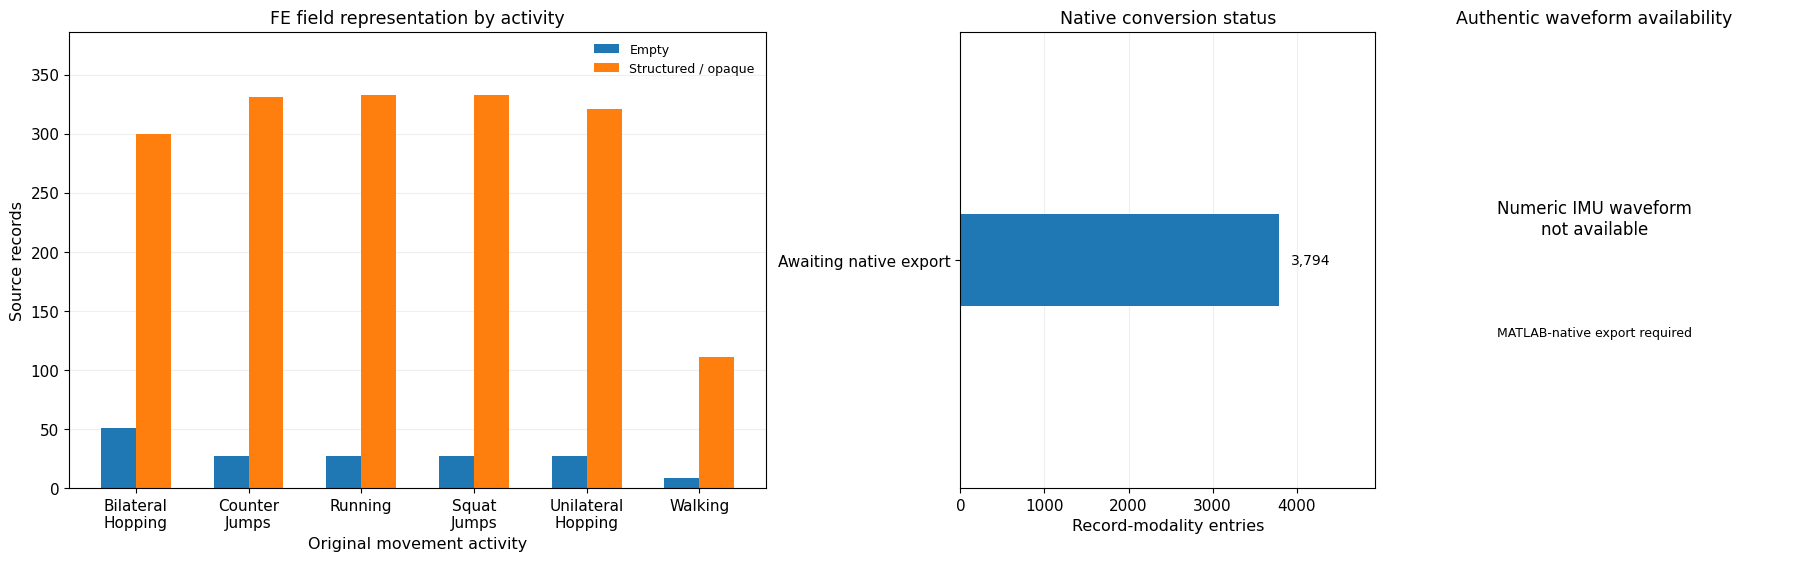

In [9]:
# ============ 08. Source Representation and Numeric Export Figure ============

# --------------- 1. Create the Single-Row, Three-Panel Figure ----------------
fig, axes = plt.subplots(
    1, 3, figsize=(18, 5.5),
    gridspec_kw={"width_ratios": [2.1, 1.25, 1.25]},
    constrained_layout=True,
)


# ------------ 2. Compare Original FE Representations by Activity -------------
plot_table = (
    original_fe.pivot(
        index="task", columns="fe_representation", values="records"
    ).fillna(0).astype(int).sort_index()
)
activity_labels = {
    "BilateralHopping": "Bilateral\nHopping",
    "CounterJumps": "Counter\nJumps",
    "Running": "Running",
    "SquatJumps": "Squat\nJumps",
    "UnilateralHopping": "Unilateral\nHopping",
    "Walking": "Walking",
}
positions = np.arange(len(plot_table))
bar_width = 0.31
empty_counts = plot_table.get(
    "empty", pd.Series(0, index=plot_table.index)
).to_numpy()
opaque_counts = plot_table.get(
    "structured_or_opaque", pd.Series(0, index=plot_table.index)
).to_numpy()

axes[0].bar(
    positions - bar_width / 2, empty_counts,
    width=bar_width, label="Empty",
)
axes[0].bar(
    positions + bar_width / 2, opaque_counts,
    width=bar_width, label="Structured / opaque",
)
axes[0].set_xticks(positions)
axes[0].set_xticklabels(
    [activity_labels.get(task, task) for task in plot_table.index]
)
axes[0].set_title("FE field representation by activity")
axes[0].set_xlabel("Original movement activity")
axes[0].set_ylabel("Source records")
axes[0].set_ylim(0, max(opaque_counts.max(), empty_counts.max()) * 1.16)
axes[0].legend(frameon=False, loc="upper right", fontsize=9)
axes[0].grid(axis="y", alpha=0.20)
axes[0].set_axisbelow(True)


# -------- 3. Show Native Conversion Status with Slim Horizontal Bars ---------
status_counts = (
    conversion_status.groupby("status")["records"].sum().sort_values()
)
status_names = {
    "awaiting_native_export": "Awaiting native export",
    "exported": "Numeric arrays exported",
    "empty": "Empty source fields",
    "unsupported_class": "Unsupported source class",
    "unsupported_column": "Unsupported column",
    "nonfinite": "Non-finite values",
    "duplicate_columns": "Duplicate column labels",
}
y = np.arange(len(status_counts))
axes[1].barh(
    y, status_counts.to_numpy(), height=0.30,
)
axes[1].set_yticks(y)
axes[1].set_yticklabels(
    [status_names.get(str(name), str(name).replace("_", " "))
     for name in status_counts.index]
)
axes[1].set_xlim(0, max(status_counts.max() * 1.30, 1))
axes[1].set_ylim(-0.75, len(y) - 0.25)
for row, count in enumerate(status_counts.to_numpy()):
    axes[1].text(
        count + max(status_counts.max() * 0.035, 1), row,
        f"{int(count):,}", va="center", fontsize=10,
    )
axes[1].set_title("Native conversion status")
axes[1].set_xlabel("Record-modality entries")
axes[1].grid(axis="x", alpha=0.20)
axes[1].set_axisbelow(True)


# ------------ 4. Show Only a Validated Original Numeric IMU Trace ------------
imu_exports = (
    native_manifest.loc[
        (native_manifest["modality"] == "IMU")
        & (native_manifest["status"] == "exported")
    ] if has_export else pd.DataFrame()
)

if not imu_exports.empty:
    candidate = imu_exports.iloc[0]
    native_path = validated_dir / candidate["export_relpath"]
    values = loadmat(
        native_path, variable_names=["values"]
    )["values"]
    axes[2].plot(np.arange(values.shape[0]), values[:, 0], linewidth=1.6)
    axes[2].set_title("Authentic numeric IMU column")
    axes[2].set_xlabel("Source sample index")
    axes[2].set_ylabel("Numerical value (units unverified)")
    axes[2].grid(alpha=0.20)
else:
    axes[2].text(
        0.5, 0.59, "Numeric IMU waveform\nnot available",
        ha="center", va="center", fontsize=12,
        transform=axes[2].transAxes,
    )
    axes[2].text(
        0.5, 0.34, "MATLAB-native export required",
        ha="center", va="center", fontsize=9,
        transform=axes[2].transAxes,
    )
    axes[2].set_title("Authentic waveform availability")
    axes[2].set_xticks([])
    axes[2].set_yticks([])
    for spine in axes[2].spines.values():
        spine.set_visible(False)


# ---------------- 5. Save the Original Source-Evidence Figure ----------------
save_figure(fig, output_dir / "04_native_conversion_evidence.png")
plt.show()

**09. Scientific Quality Gate and Provenance Record**

The data-source gate retains its previous PASS. Numeric extraction is graded independently as `AWAITING_NATIVE_EXPORT`, `NATIVE_MANIFEST_VALIDATED_NO_NUMERIC_PAYLOADS` or `NUMERIC_PAYLOADS_VALIDATED`. **Neither state is equivalent to model readiness.** An exported numerical matrix can still lack verified channel identities, physical units, source FE sign convention and correct IMU/FE temporal pairing.

The supplied numeric-export archive SHA256 (if any) must be recorded separately from the Figshare original archive fingerprint. This saved execution had **no export ZIP**. The extraction method must be identified accurately in the export provenance, whether Python mat-io or MATLAB-native; the existing `native_conversion_gate` key remains unchanged to preserve historical comparability.

In [10]:
# ============== 09. Original Source and Conversion Quality Gate ==============

# ----------- 1. Enforce Source Identity and Scientific Separation ------------
assert len(registry)==1897 and registry["subject_id"].nunique()==40
assert prior02["archive_sha256"]==prior03["archive_sha256"]
assert int(original_fe["records"].sum())==len(registry)
assert not native_summary["model_ready"]
if not has_export:
    conversion_state = "AWAITING_NATIVE_EXPORT"
elif native_summary["validated_finite_payloads"] > 0:
    conversion_state = "NUMERIC_PAYLOADS_VALIDATED"
else:
    conversion_state = "NATIVE_MANIFEST_VALIDATED_NO_NUMERIC_PAYLOADS"
gate = {
    "source_article":30225739,
    "source_version":13,
    "original_matlab_zip_sha256":prior03["archive_sha256"],
    "source_record_count":1897,"participant_count":40,
    "fe_empty_source_records":168,
    "native_export_supplied":bool(has_export),
    "native_export_sha256":sha256_file(native_archive) if has_export else None,
    "original_source_gate":"PASSED",
    "native_conversion_gate":conversion_state,
    "numeric_export_audit":native_summary,
    "physical_imu_units_verified":False,
    "physical_fe_units_verified":False,
    "fe_timestep_alignment_verified":False,
    "model_ready":False,
    "model_training_performed":False,
}
(output_dir/"04_native_conversion_quality_gate.json").write_text(
    json.dumps(gate,indent=2)+"\n",encoding="utf-8"
)
print("ORIGINAL SOURCE INTEGRITY: PASSED")
print("NATIVE NUMERIC CONVERSION:",conversion_state)
print("SUPERVISED REGRESSION READINESS: NOT VERIFIED")

ORIGINAL SOURCE INTEGRITY: PASSED
NATIVE NUMERIC CONVERSION: AWAITING_NATIVE_EXPORT
SUPERVISED REGRESSION READINESS: NOT VERIFIED


**10. Scientific Evidence Export and Next Boundary**

Store eight `04_*` research outputs: the source conversion contract, source-linked conversion manifest, conversion statuses, numeric payload validity, grid candidates, semantic checks, one descriptive PNG and the JSON Quality Gate report.

**Recorded result:** The completed source-backed execution generated all eight `04_*` outputs and recorded `original_source_gate: PASSED`, `native_conversion_gate: AWAITING_NATIVE_EXPORT` and `model_ready: false`. No MATLAB-native export ZIP or validated numeric IMU/FE payload was available. The workflow SVG above is grounded in this state; it does **not** imply that physical units, strain semantics or time-grid alignment have been established.

**Final visualisation and archive:** The revised single-row, three-panel figure was executed successfully and the updated `04_native_conversion_evidence.png` was committed to GitHub alongside the seven other `04_*` evidence files. The first panel compares empty and opaque FE source fields with adjacent bars, the second presents the 3,794 record-modality entries awaiting native export, and the third reports authentic waveform unavailability. The dedicated `04_workflow.svg` is embedded above with no stage number in its visible title. No original numeric export ZIP was available **during this execution**. Notebook 05 now tests the **Python-first** recovery option, while the MATLAB exporter remains an optional fallback. Both require independent numeric and biomechanical validation. Original numeric MAT payloads must remain in private raw-data storage rather than being committed to the public repository.

In [11]:
# ============= 10. Research Output Registry and Colab Packaging ==============

# --------------------- 1. Check Required Evidence Files ----------------------
expected=[
    "04_expected_conversion_contract.csv",
    "04_native_conversion_manifest.csv",
    "04_conversion_status_summary.csv",
    "04_numeric_payload_validation.csv",
    "04_numeric_grid_candidates.csv",
    "04_temporal_semantics_audit.csv",
    "04_native_conversion_evidence.png",
    "04_native_conversion_quality_gate.json",
]
missing=[name for name in expected if not (output_dir/name).is_file()]
if missing:
    raise FileNotFoundError("Missing conversion audit files: "+", ".join(missing))
print("Notebook 04 evidence files:",len(expected))

# -------- 2. Package Only Summary Outputs, Never Source Numeric Data ---------
download_outputs_from_colab(
    folder="biomechanical_load_estimation/output",stage="04"
)

Notebook 04 evidence files: 8
------------------------------------------------------------------------
Notebook stage: 04
Files packaged: 8
  + 04_conversion_status_summary.csv
  + 04_expected_conversion_contract.csv
  + 04_native_conversion_evidence.png
  + 04_native_conversion_manifest.csv
  + 04_native_conversion_quality_gate.json
  + 04_numeric_grid_candidates.csv
  + 04_numeric_payload_validation.csv
  + 04_temporal_semantics_audit.csv
Download ZIP from Colab Contents: /content/biomechanical_load_estimation_Stage_04_Outputs.zip
GitHub Commit/Push performed: NO
